Бизнес-кейс: «Когортный анализ (retention)»

Необходимо узнать насколько хорошо удерживаются клиенты. 

Разбиваем пользователей на когорты по месяцу их первой покупки и смотрим, какое количество возвращается в следующие месяцы

Для анализа использовалась таблица в PostgreSQL:

**1. `user_purchases` (Исходная таблица)**
| Поле | Тип | Описание |
| :--- | :--- | :--- |
| `user_id` | INTEGER | ID уникальных пользователей |
| `purchase_date` | DATE | Первое число месяца когорты |

## Как это работает
1. Данные агрегируются через SQL-запрос (Нахождение даты первой покупки пользователя. Расчет разницы в месяцах между покупкой и первой покупкой. Подсчет количества уникальных пользователей для каждого месяца когорты).
2. Результат выгружается в CSV и загружается в Jupyter Notebook.

1. Загружаем данные от SQL

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных
df_cohort=pd.read_csv('cohort_data.csv')
print("Данные для анализа:")
print(df_cohort)

Данные для анализа:
   Кол-во уникальных пользователей           Месяц когорты  \
0                                5  2024-01-01 00:00:00+03   
1                                3  2024-01-01 00:00:00+03   
2                                3  2024-01-01 00:00:00+03   
3                                4  2024-02-01 00:00:00+03   
4                                2  2024-02-01 00:00:00+03   
5                                3  2024-03-01 00:00:00+03   

   Разница между покупками  
0                        0  
1                        1  
2                        2  
3                        0  
4                        1  
5                        0  


In [ ]:
# 2. Переименовываем столбцы
df_cohort.columns = ['count','cohort','month_diff']

# 3. Переименовываем столбец cohort
translate_dict={
    '2024-01-01 00:00:00+03':'Январь',
    '2024-02-01 00:00:00+03':'Февраль',
    '2024-03-01 00:00:00+03':'Март'
}
df_cohort['cohort']=df_cohort['cohort'].replace(translate_dict)

print("Данные для анализа:")
print(df_cohort)

Данные для анализа:
   count   cohort  month_diff
0      5   Январь           0
1      3   Январь           1
2      3   Январь           2
3      4  Февраль           0
4      2  Февраль           1
5      3     Март           0


In [26]:
# 4. Строим сводную таблицу
cohort_pivot=df_cohort.pivot_table(
    index='cohort',
    columns='month_diff',
    values='count',
    aggfunc='sum' #Просто показывает значение
)
cohort_pivot=cohort_pivot.fillna(0) #Убираем NaN
cohort_pivot=cohort_pivot.reindex(['Январь','Февраль','Март']) #Сортируем месяцы (начало с января)
cohort_pivot.columns=['0 месяц','1 месяц','2 месяц']

print(cohort_pivot)

         0 месяц  1 месяц  2 месяц
cohort                            
Январь       5.0      3.0      3.0
Февраль      4.0      2.0      0.0
Март         3.0      0.0      0.0


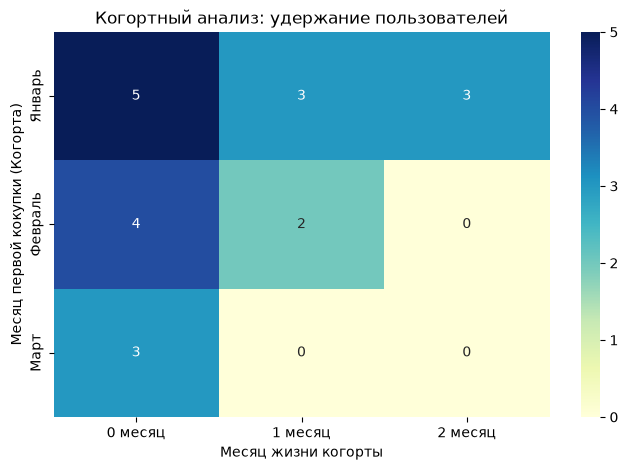

In [28]:
#5 Строим тепловую карту
plt.figure(figsize=(8,5))
ax=sns.heatmap(cohort_pivot,annot=True, cmap='YlGnBu',fmt='g') #annot=True выводит цифры внутри ячеек, cmap= 'YlGnBu' цветовая схема(желтый, зеленый, синий), fmt='g' убирает нули после запятой

ax.set_title('Когортный анализ: удержание пользователей')
ax.set_xlabel('Месяц жизни когорты')
ax.set_ylabel('Месяц первой кокупки (Когорта)')
plt.show()

Выводы по анализу когорты пользователей:

**1. Январская когорта (5 человек):** Из 5 клиентов 3 вернулись в феврале и 3 вернулись в марте. Высокий уровень удержание тех кто пришел в январе.

**2. Февральская когорта (4 человека):** Из 4 клиентов 2 вернулись в марте. Удержание чуть ниже чем в январе.

**3. Мартовская когорта (3 человека):** Новых клиентов - 3 человека. Удержание пока неизвестно т.к. нет данных за следующие месяцы.

**4. Общий тренд:** Количество активных клиентов снижается. Для повышения удержания следует проанализировать, какие действия предлагали вернувшимся клиентам, и предложить эти же действия тем, кто ушел.